**Random Forest Classification Implementation**<br>
**Holiday Package Prediction**<br>
**Problem Statement**
- 5 types of packages are there "Basic, Standard, Deluxe, Super Deluxe, King
- 18% of customers purchased the packages

**New Product - Wellness Tourism Package**
- To maintain enhance, kick start a healthy lifestyle


**Goal**<br>
Company wants to use the current data to make the marketing expenditure more efficient

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

In [2]:
# import kagglehub
# # Download latest version
# kagglehub.dataset_download("susant4learning/holiday-package-purchase-prediction")

In [3]:
df=pd.read_csv("Travel.csv")
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [4]:
# Data Cleaning
# Handle Missing Values
# Handle Duplicates
# Check data types
# Understand the dataset

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4888 entries, 0 to 4887
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CustomerID                4888 non-null   int64  
 1   ProdTaken                 4888 non-null   int64  
 2   Age                       4662 non-null   float64
 3   TypeofContact             4863 non-null   str    
 4   CityTier                  4888 non-null   int64  
 5   DurationOfPitch           4637 non-null   float64
 6   Occupation                4888 non-null   str    
 7   Gender                    4888 non-null   str    
 8   NumberOfPersonVisiting    4888 non-null   int64  
 9   NumberOfFollowups         4843 non-null   float64
 10  ProductPitched            4888 non-null   str    
 11  PreferredPropertyStar     4862 non-null   float64
 12  MaritalStatus             4888 non-null   str    
 13  NumberOfTrips             4748 non-null   float64
 14  Passport           

In [6]:
df.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

In [7]:
## In Categorical Features -- Lets check if it is balanced or imbalanced
print(df["Gender"].value_counts())

Gender
Male       2916
Female     1817
Fe Male     155
Name: count, dtype: int64


In [8]:
print(df["TypeofContact"].value_counts())

TypeofContact
Self Enquiry       3444
Company Invited    1419
Name: count, dtype: int64


In [9]:
print(df["Occupation"].value_counts())

Occupation
Salaried          2368
Small Business    2084
Large Business     434
Free Lancer          2
Name: count, dtype: int64


In [10]:
print(df["ProductPitched"].value_counts())

ProductPitched
Basic           1842
Deluxe          1732
Standard         742
Super Deluxe     342
King             230
Name: count, dtype: int64


In [11]:
print(df["MaritalStatus"].value_counts())

MaritalStatus
Married      2340
Divorced      950
Single        916
Unmarried     682
Name: count, dtype: int64


In [12]:
print(df["Designation"].value_counts())

Designation
Executive         1842
Manager           1732
Senior Manager     742
AVP                342
VP                 230
Name: count, dtype: int64


In [13]:
## Value Fix required only for Gender Category
df["Gender"].value_counts()

Gender
Male       2916
Female     1817
Fe Male     155
Name: count, dtype: int64

In [14]:
df["Gender"]=np.where(df["Gender"].str.contains("Fe"),"Female","Male")

In [15]:
df["Gender"].value_counts()

Gender
Male      2916
Female    1972
Name: count, dtype: int64

In [16]:
df["Gender"].value_counts()

Gender
Male      2916
Female    1972
Name: count, dtype: int64

In [17]:
## Other Process -- 
## df["Gender"]=df["Gender"].replace("Fe Male","Female")

In [18]:
df["MaritalStatus"]=df["MaritalStatus"].replace("Single","Unmarried")

In [19]:
df["MaritalStatus"].value_counts()

MaritalStatus
Married      2340
Unmarried    1598
Divorced      950
Name: count, dtype: int64

In [20]:
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Unmarried,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [21]:
## Checking for Missing Values
## Features with NaN/nan Values

features_with_na=[feature for feature in df.columns if df[feature].isnull().sum()>0 ]
features_with_na

['Age',
 'TypeofContact',
 'DurationOfPitch',
 'NumberOfFollowups',
 'PreferredPropertyStar',
 'NumberOfTrips',
 'NumberOfChildrenVisiting',
 'MonthlyIncome']

In [22]:
for feature in features_with_na:
    print("Missing Value % for",feature,"is",round(df[feature].isnull().mean()*100,5),"%")

Missing Value % for Age is 4.62357 %
Missing Value % for TypeofContact is 0.51146 %
Missing Value % for DurationOfPitch is 5.13502 %
Missing Value % for NumberOfFollowups is 0.92062 %
Missing Value % for PreferredPropertyStar is 0.53191 %
Missing Value % for NumberOfTrips is 2.86416 %
Missing Value % for NumberOfChildrenVisiting is 1.35025 %
Missing Value % for MonthlyIncome is 4.76678 %


In [23]:
df[features_with_na].describe()

,Age,DurationOfPitch,NumberOfFollowups,PreferredPropertyStar,NumberOfTrips,NumberOfChildrenVisiting,MonthlyIncome
count,4662.000000,4637.000000,4843.000000,4862.000000,4748.000000,4822.000000,4655.000000
mean,37.622265,15.490835,3.708445,3.581037,3.236521,1.187267,23619.853491
std,9.316387,8.519643,1.002509,0.798009,1.849019,0.857861,5380.698361
min,18.000000,5.000000,1.000000,3.000000,1.000000,0.000000,1000.000000
25%,31.000000,9.000000,3.000000,3.000000,2.000000,1.000000,20346.000000
50%,36.000000,13.000000,4.000000,3.000000,3.000000,1.000000,22347.000000
75%,44.000000,20.000000,4.000000,4.000000,4.000000,2.000000,25571.000000
max,61.000000,127.000000,6.000000,5.000000,22.000000,3.000000,98678.000000


In [24]:
## We can see Mean and Median are almost similar
## Here we will follow Median Impution, since even if there will be outlier it will not be effected with it

In [25]:
# Impute Median Value of Age Column
# Impute Mode of Type of Contract
# Impute Median for Duration of Pitch
# Impute Mode for NumberofFollowup as it is Discrete feature
# Impute Mode for PreferredPropertyStar
# Impute Median for Number of Trips
# Impute Mode for NumberofChildrenVisiting
# Impute Median for MonthlyIncome

In [26]:
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 4888 entries, 0 to 4887
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CustomerID                4888 non-null   int64  
 1   ProdTaken                 4888 non-null   int64  
 2   Age                       4662 non-null   float64
 3   TypeofContact             4863 non-null   str    
 4   CityTier                  4888 non-null   int64  
 5   DurationOfPitch           4637 non-null   float64
 6   Occupation                4888 non-null   str    
 7   Gender                    4888 non-null   str    
 8   NumberOfPersonVisiting    4888 non-null   int64  
 9   NumberOfFollowups         4843 non-null   float64
 10  ProductPitched            4888 non-null   str    
 11  PreferredPropertyStar     4862 non-null   float64
 12  MaritalStatus             4888 non-null   str    
 13  NumberOfTrips             4748 non-null   float64
 14  Passport           

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Unmarried,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [27]:
# Age
df["Age"]=df["Age"].fillna(df["Age"].median())

# Type of Contract
df["TypeofContact"]=df["TypeofContact"].fillna(df["TypeofContact"].mode()[0])

# Duration of Pitch
df["DurationOfPitch"]=df["DurationOfPitch"].fillna(df["DurationOfPitch"].median())

# No. of Followups
df["NumberOfFollowups"]=df["NumberOfFollowups"].fillna(df["NumberOfFollowups"].mode()[0])

# PreferredPropertyStar
df["PreferredPropertyStar"]=df["PreferredPropertyStar"].fillna(df["PreferredPropertyStar"].mode()[0])

# NumberOfTrips
df["NumberOfTrips"]=df["NumberOfTrips"].fillna(df["NumberOfTrips"].median())

# NumberOfChildrenVisiting
df["NumberOfChildrenVisiting"]=df["NumberOfChildrenVisiting"].fillna(df["NumberOfChildrenVisiting"].mode()[0])

# MonthlyIncome
df["MonthlyIncome"]=df["MonthlyIncome"].fillna(df["MonthlyIncome"].median())


In [28]:
df.isnull().sum()

CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4888 entries, 0 to 4887
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CustomerID                4888 non-null   int64  
 1   ProdTaken                 4888 non-null   int64  
 2   Age                       4888 non-null   float64
 3   TypeofContact             4888 non-null   str    
 4   CityTier                  4888 non-null   int64  
 5   DurationOfPitch           4888 non-null   float64
 6   Occupation                4888 non-null   str    
 7   Gender                    4888 non-null   str    
 8   NumberOfPersonVisiting    4888 non-null   int64  
 9   NumberOfFollowups         4888 non-null   float64
 10  ProductPitched            4888 non-null   str    
 11  PreferredPropertyStar     4888 non-null   float64
 12  MaritalStatus             4888 non-null   str    
 13  NumberOfTrips             4888 non-null   float64
 14  Passport           

In [30]:
# Dropping Customer ID
df.drop(columns=["CustomerID"],inplace=True)

In [31]:
df.head()

,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,0.0,Manager,20993.0
1,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Unmarried,7.0,1,3,0,0.0,Executive,17090.0
3,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,0,36.0,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


## Feature Engineering
### Feature Extraction

In [32]:
## Create TotalVisiting column -- remove redundant feature No. of Person and No. of Children

df["TotalVisiting"]=df["NumberOfPersonVisiting"]+df["NumberOfChildrenVisiting"]
df.drop(columns=["NumberOfPersonVisiting","NumberOfChildrenVisiting"],inplace=True)

In [33]:
df.head()

,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,Designation,MonthlyIncome,TotalVisiting
0,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,Manager,20993.0,3.0
1,0,49.0,Company Invited,1,14.0,Salaried,Male,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,Manager,20130.0,5.0
2,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,4.0,Basic,3.0,Unmarried,7.0,1,3,0,Executive,17090.0,3.0
3,0,33.0,Company Invited,1,9.0,Salaried,Female,3.0,Basic,3.0,Divorced,2.0,1,5,1,Executive,17909.0,3.0
4,0,36.0,Self Enquiry,1,8.0,Small Business,Male,3.0,Basic,4.0,Divorced,1.0,0,5,1,Executive,18468.0,2.0


In [34]:
## Get All Numerical Columns and Get all Categorical Columns
num_features=[feature for feature in df.columns if df[feature].dtype!="string"]
num_features

['ProdTaken',
 'Age',
 'CityTier',
 'DurationOfPitch',
 'NumberOfFollowups',
 'PreferredPropertyStar',
 'NumberOfTrips',
 'Passport',
 'PitchSatisfactionScore',
 'OwnCar',
 'MonthlyIncome',
 'TotalVisiting']

In [35]:
cat_features=[feature for feature in df.columns if feature not in num_features]
cat_features

['TypeofContact',
 'Occupation',
 'Gender',
 'ProductPitched',
 'MaritalStatus',
 'Designation']

In [36]:
## Discrete and Continous Features
discrete=[feature for feature in df.columns if len(df[feature].unique())<=25]
discrete

['ProdTaken',
 'TypeofContact',
 'CityTier',
 'Occupation',
 'Gender',
 'NumberOfFollowups',
 'ProductPitched',
 'PreferredPropertyStar',
 'MaritalStatus',
 'NumberOfTrips',
 'Passport',
 'PitchSatisfactionScore',
 'OwnCar',
 'Designation',
 'TotalVisiting']

In [37]:
continous=[feature for feature in df.columns if len(df[feature].unique())>25]
continous

['Age', 'DurationOfPitch', 'MonthlyIncome']

In [38]:
## Handling Categorical Data Feature Engineering for Model Training

In [39]:
df.head()

,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,Designation,MonthlyIncome,TotalVisiting
0,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,Manager,20993.0,3.0
1,0,49.0,Company Invited,1,14.0,Salaried,Male,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,Manager,20130.0,5.0
2,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,4.0,Basic,3.0,Unmarried,7.0,1,3,0,Executive,17090.0,3.0
3,0,33.0,Company Invited,1,9.0,Salaried,Female,3.0,Basic,3.0,Divorced,2.0,1,5,1,Executive,17909.0,3.0
4,0,36.0,Self Enquiry,1,8.0,Small Business,Male,3.0,Basic,4.0,Divorced,1.0,0,5,1,Executive,18468.0,2.0


In [40]:
## Column Transformer, OneHotEncoding, Binary Encoding

## Defining the independent and dependent variable
X=df.drop(columns=["ProdTaken"])
y=df["ProdTaken"]

In [41]:
X

,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,Designation,MonthlyIncome,TotalVisiting
0,41.0,Self Enquiry,3,6.0,Salaried,Female,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,Manager,20993.0,3.0
1,49.0,Company Invited,1,14.0,Salaried,Male,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,Manager,20130.0,5.0
2,37.0,Self Enquiry,1,8.0,Free Lancer,Male,4.0,Basic,3.0,Unmarried,7.0,1,3,0,Executive,17090.0,3.0
3,33.0,Company Invited,1,9.0,Salaried,Female,3.0,Basic,3.0,Divorced,2.0,1,5,1,Executive,17909.0,3.0
4,36.0,Self Enquiry,1,8.0,Small Business,Male,3.0,Basic,4.0,Divorced,1.0,0,5,1,Executive,18468.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4883,49.0,Self Enquiry,3,9.0,Small Business,Male,5.0,Deluxe,4.0,Unmarried,2.0,1,1,1,Manager,26576.0,4.0
4884,28.0,Company Invited,1,31.0,Salaried,Male,5.0,Basic,3.0,Unmarried,3.0,1,3,1,Executive,21212.0,6.0
4885,52.0,Self Enquiry,3,17.0,Salaried,Female,4.0,Standard,4.0,Married,7.0,0,1,1,Senior Manager,31820.0,7.0
4886,19.0,Self Enquiry,3,16.0,Small Business,Male,4.0,Basic,3.0,Unmarried,3.0,0,5,0,Executive,20289.0,5.0


In [42]:
y.value_counts()

ProdTaken
0    3968
1     920
Name: count, dtype: int64

In [43]:
## The Data is imbalanced
## Ensemble Techniques -- perform well even with imbalanced dataset

In [44]:
## Before that we will perform the split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [45]:
X_train.shape,X_test.shape

((3910, 17), (978, 17))

In [46]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 4888 entries, 0 to 4887
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     4888 non-null   float64
 1   TypeofContact           4888 non-null   str    
 2   CityTier                4888 non-null   int64  
 3   DurationOfPitch         4888 non-null   float64
 4   Occupation              4888 non-null   str    
 5   Gender                  4888 non-null   str    
 6   NumberOfFollowups       4888 non-null   float64
 7   ProductPitched          4888 non-null   str    
 8   PreferredPropertyStar   4888 non-null   float64
 9   MaritalStatus           4888 non-null   str    
 10  NumberOfTrips           4888 non-null   float64
 11  Passport                4888 non-null   int64  
 12  PitchSatisfactionScore  4888 non-null   int64  
 13  OwnCar                  4888 non-null   int64  
 14  Designation             4888 non-null   str    
 15

In [47]:
cat_features=X.select_dtypes(include="string").columns
num_features=X.select_dtypes(exclude="string").columns

In [48]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

numeric_transformer= StandardScaler()
oh_transformer=OneHotEncoder(drop="first")

preprocessor=ColumnTransformer(
    [
        ("OneHotEncoder",oh_transformer,cat_features),
        ("StandardScaler",numeric_transformer,num_features)
    ]
)

In [49]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('OneHotEncoder', ...), ('StandardScaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``f

In [50]:
X_train=preprocessor.fit_transform(X_train)
X_test=preprocessor.transform(X_test)

In [51]:
pd.DataFrame(X_train)

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,-0.721400,-1.020350,1.284279,-0.725271,-0.127737,-0.632399,0.679690,0.782966,-0.382245,-0.774151
1,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,-0.721400,0.690023,0.282777,-0.725271,1.511598,-0.632399,0.679690,0.782966,-0.459799,0.643615
2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.721400,-1.020350,0.282777,1.771041,0.418708,-0.632399,0.679690,0.782966,-0.245196,-0.065268
3,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,-0.721400,-1.020350,1.284279,-0.725271,-0.127737,-0.632399,1.408395,-1.277194,0.213475,-0.065268
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.721400,2.400396,-1.720227,-0.725271,1.511598,-0.632399,-0.049015,-1.277194,-0.024889,2.061382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3905,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,-0.721400,-0.653841,1.284279,-0.725271,-0.674182,-0.632399,-1.506426,0.782966,-0.536973,0.643615
3906,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.455047,-0.898180,-0.718725,1.771041,-1.220627,-0.632399,1.408395,0.782966,1.529609,-0.065268
3907,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.455047,1.545210,0.282777,-0.725271,2.058043,-0.632399,-0.777720,0.782966,-0.360576,0.643615
3908,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.455047,1.789549,1.284279,-0.725271,-0.127737,-0.632399,-1.506426,0.782966,-0.252799,0.643615


In [52]:
preprocessor.get_feature_names_out()

array(['OneHotEncoder__TypeofContact_Self Enquiry',
       'OneHotEncoder__Occupation_Large Business',
       'OneHotEncoder__Occupation_Salaried',
       'OneHotEncoder__Occupation_Small Business',
       'OneHotEncoder__Gender_Male',
       'OneHotEncoder__ProductPitched_Deluxe',
       'OneHotEncoder__ProductPitched_King',
       'OneHotEncoder__ProductPitched_Standard',
       'OneHotEncoder__ProductPitched_Super Deluxe',
       'OneHotEncoder__MaritalStatus_Married',
       'OneHotEncoder__MaritalStatus_Unmarried',
       'OneHotEncoder__Designation_Executive',
       'OneHotEncoder__Designation_Manager',
       'OneHotEncoder__Designation_Senior Manager',
       'OneHotEncoder__Designation_VP', 'StandardScaler__Age',
       'StandardScaler__CityTier', 'StandardScaler__DurationOfPitch',
       'StandardScaler__NumberOfFollowups',
       'StandardScaler__PreferredPropertyStar',
       'StandardScaler__NumberOfTrips', 'StandardScaler__Passport',
       'StandardScaler__PitchSatisfac

**Random Forest Classifier Training**

In [53]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,precision_score,recall_score,f1_score,roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [54]:
## We cannot be dependent on one model, we need to try many models
models={
    "Random Forest":RandomForestClassifier(),
    "Decision Tree":DecisionTreeClassifier(),
    "Logistic Regression":LogisticRegression(),
    "KNeighborsClassifier":KNeighborsClassifier(n_neighbors=10),
    "SVC":SVC()
}
# for i in range(len(list(models))):
#     model=list(models.values())[i]
#     model.fit(X_train,X_test) # Train Model


# I could ahve also used below loop
for k,v in models.items():
    print("-"*30)
    print(k)
    print("-"*30)
    model=v
    model.fit(X_train,y_train)
    # make predictions
    y_train_pred=model.predict(X_train)
    y_test_pred=model.predict(X_test)
    # Training performance
    model_train_accuracy=accuracy_score(y_train,y_train_pred)
    model_train_f1=f1_score(y_train,y_train_pred,average="weighted")
    model_train_precision=precision_score(y_train,y_train_pred)
    model_train_recall=recall_score(y_train,y_train_pred)
    model_train_roauc_score=roc_auc_score(y_train,y_train_pred)
    # Test performance
    model_test_accuracy=accuracy_score(y_test,y_test_pred)
    model_test_f1=f1_score(y_test,y_test_pred,average="weighted")
    model_test_precision=precision_score(y_test,y_test_pred)
    model_test_recall=recall_score(y_test,y_test_pred)
    model_test_roauc_score=roc_auc_score(y_test,y_test_pred)
    print("Training Performance :")
    print(model_train_accuracy,model_train_f1,model_train_precision,model_train_recall,model_train_roauc_score)
    print("Testing Performance :")
    print(model_test_accuracy,model_test_f1,model_test_precision,model_test_recall,model_test_roauc_score)
    print()

------------------------------
Random Forest
------------------------------
Training Performance :
1.0 1.0 1.0 1.0 1.0
Testing Performance :
0.9233128834355828 0.9167227895034895 0.967741935483871 0.6282722513089005 0.8115948295934591

------------------------------
Decision Tree
------------------------------
Training Performance :
1.0 1.0 1.0 1.0 1.0
Testing Performance :
0.9243353783231084 0.9233946314505503 0.8268156424581006 0.774869109947644 0.8677395105011411

------------------------------
Logistic Regression
------------------------------
Training Performance :
0.8460358056265984 0.8202118738880438 0.7015873015873015 0.30315500685871055 0.6368022755136056
Testing Performance :
0.83640081799591 0.8086633047343356 0.691358024691358 0.2931937172774869 0.630713758257549

------------------------------
KNeighborsClassifier
------------------------------
Training Performance :
0.8833759590792839 0.8643695420785873 0.9226006191950464 0.40877914951989025 0.7004599928674585
Testing Per

In [55]:
## Recall --- 
## Precision -- False Positive



#         Positive Negative
# Positive TP         FP
# Negative FN         TN


# Precision = TP/TP+FP (Will try to minimize the FP error (False Alarm (Positive) Cases))
# Recall=TP/TP+FN --- More Recall Score --- (Will try to minimize the FN error (FN -- missed positive cases))
# ROC -- TPR (y) vs FPR (x)

In [56]:
## Hyper Parameter Tuning with Random Forest
params={
    "max_depth":[5,8,15,None,10],
    "n_estimators":[100,200,500,1000],
    "min_samples_split":[2,8,15,20],
    "max_features":[5,7,"auto",8]
}

In [57]:
params

{'max_depth': [5, 8, 15, None, 10],
 'n_estimators': [100, 200, 500, 1000],
 'min_samples_split': [2, 8, 15, 20],
 'max_features': [5, 7, 'auto', 8]}

In [58]:
## Models List for Hyperparameter tuning
randomcv_models=[
    ("RF",RandomForestClassifier(),params)
]

In [59]:
from sklearn.model_selection import RandomizedSearchCV
model_param={}
for name,model,param in randomcv_models:
    random=RandomizedSearchCV(estimator=model,param_distributions=param,n_iter=100,cv=3,verbose=2,n_jobs=-1)
    random.fit(X_train,y_train)
    model_param[name]=random.best_params_

for model_name in model_param:
    print("Best Param for",model_name)
    print(model_param[model_name])

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best Param for RF
{'n_estimators': 500, 'min_samples_split': 2, 'max_features': 7, 'max_depth': None}


In [60]:
## We cannot be dependent on one model, we need to try many models
models={
    "Random Forest":RandomForestClassifier(),
    "Random Forest Tuned":RandomForestClassifier(n_estimators=500, min_samples_split=2, max_features=7, max_depth=None),
    "Decision Tree":DecisionTreeClassifier(),
    "Logistic Regression":LogisticRegression(),
    "KNeighborsClassifier":KNeighborsClassifier(n_neighbors=10),
    "SVC":SVC()
}
# for i in range(len(list(models))):
#     model=list(models.values())[i]
#     model.fit(X_train,X_test) # Train Model


# I could ahve also used below loop
for k,v in models.items():
    print("-"*30)
    print(k)
    print("-"*30)
    model=v
    model.fit(X_train,y_train)
    # make predictions
    y_train_pred=model.predict(X_train)
    y_test_pred=model.predict(X_test)
    # Training performance
    model_train_accuracy=accuracy_score(y_train,y_train_pred)
    model_train_f1=f1_score(y_train,y_train_pred,average="weighted")
    model_train_precision=precision_score(y_train,y_train_pred)
    model_train_recall=recall_score(y_train,y_train_pred)
    model_train_roauc_score=roc_auc_score(y_train,y_train_pred)
    # Test performance
    model_test_accuracy=accuracy_score(y_test,y_test_pred)
    model_test_f1=f1_score(y_test,y_test_pred,average="weighted")
    model_test_precision=precision_score(y_test,y_test_pred)
    model_test_recall=recall_score(y_test,y_test_pred)
    model_test_roauc_score=roc_auc_score(y_test,y_test_pred)
    print("Training Performance :")
    print(model_train_accuracy,model_train_f1,model_train_precision,model_train_recall,model_train_roauc_score)
    print("Testing Performance :")
    print(model_test_accuracy,model_test_f1,model_test_precision,model_test_recall,model_test_roauc_score)
    print()

------------------------------
Random Forest
------------------------------
Training Performance :
1.0 1.0 1.0 1.0 1.0
Testing Performance :
0.9314928425357873 0.9266823819255425 0.9626865671641791 0.675392670157068 0.8345197150022953

------------------------------
Random Forest Tuned
------------------------------
Training Performance :
1.0 1.0 1.0 1.0 1.0
Testing Performance :
0.9325153374233128 0.9280794148929716 0.9562043795620438 0.6858638743455497 0.8391199930812882

------------------------------
Decision Tree
------------------------------
Training Performance :
1.0 1.0 1.0 1.0 1.0
Testing Performance :
0.9192229038854806 0.9186478077476785 0.8043478260869565 0.774869109947644 0.8645628904249022

------------------------------
Logistic Regression
------------------------------
Training Performance :
0.8460358056265984 0.8202118738880438 0.7015873015873015 0.30315500685871055 0.6368022755136056
Testing Performance :
0.83640081799591 0.8086633047343356 0.691358024691358 0.293193

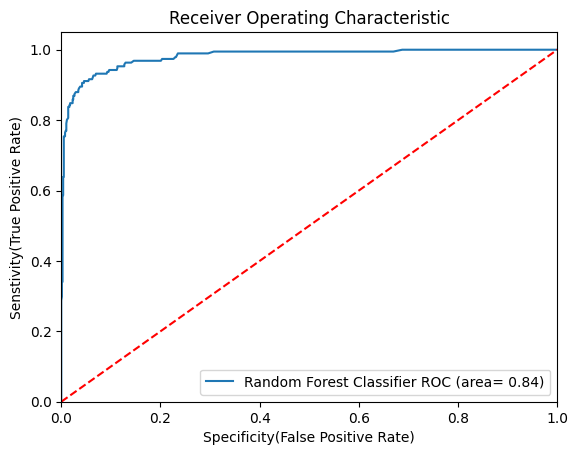

In [62]:
## ROC AUC Curve
from sklearn.metrics import roc_auc_score,roc_curve
plt.figure()

# Add the model to the list that you want to view the ROC AUC Curve
auc_models=[
    {
        "label":"Random Forest Classifier",
        "model":RandomForestClassifier(n_estimators=500, min_samples_split=2, max_features=7, max_depth=None),
        "auc":0.839
    }
]

# Create loop through all model
for algo in auc_models:
    model=algo["model"] # select the model
    model.fit(X_train,y_train) # Train the model
    #Computer False Positive rate and true positive rate
    fpr,tpr,thresholds=roc_curve(y_test,model.predict_proba(X_test)[:,1])
    # Calculate Area under curve to display plot
    plt.plot(fpr,tpr,label="%s ROC (area= %0.2f)"%(algo["label"],algo["auc"]))
    #Custom Settings for plot
    plt.plot([0,1],[0,1],"r--")
    plt.xlim([0.0,1.0])
    plt.ylim([0.0,1.05])
    plt.xlabel("Specificity(False Positive Rate)")
    plt.ylabel("Senstivity(True Positive Rate)")
    plt.title("Receiver Operating Characteristic")
    plt.legend(loc="lower right")
    plt.savefig("auc.png")
    plt.show()